In [1]:
import torch as t
import torch.nn as nn

import math
import os
import sys
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import datasets
import einops
import numpy as np
import wandb
from jaxtyping import Float, Int
from rich import print as rprint
from rich.table import Table
from torch import Tensor
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformer_lens import HookedTransformer
from transformer_lens.utils import gelu_new, tokenize_and_concatenate
from transformers import GPT2TokenizerFast

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter1_transformer_interp"
section = "part1_transformer_from_scratch"
root_dir = next(p for p in Path.cwd().parents if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part1_transformer_from_scratch.solutions as solutions
import part1_transformer_from_scratch.tests as tests

MAIN = __name__ == "__main__"


W1002 14:40:43.563000 11392 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [2]:
print(solutions.__file__)

reference_gpt2 = HookedTransformer.from_pretrained(
    "gpt2-small",
    fold_ln=False,
    center_unembed=False,
    center_writing_weights=False,  # you'll learn about these arguments later!
)

sorted_vocab = sorted(list(reference_gpt2.tokenizer.vocab.items()), key=lambda n: n[1])

print(sorted_vocab[:20])
print()
print(sorted_vocab[250:270])
print()
print(sorted_vocab[990:1010])
print()

E:\0. Project\ARENA\ARENA_materials\chapter1_transformer_interp\exercises\part1_transformer_from_scratch\solutions.py


`torch_dtype` is deprecated! Use `dtype` instead!


Loaded pretrained model gpt2-small into HookedTransformer
[('!', 0), ('"', 1), ('#', 2), ('$', 3), ('%', 4), ('&', 5), ("'", 6), ('(', 7), (')', 8), ('*', 9), ('+', 10), (',', 11), ('-', 12), ('.', 13), ('/', 14), ('0', 15), ('1', 16), ('2', 17), ('3', 18), ('4', 19)]

[('ľ', 250), ('Ŀ', 251), ('ŀ', 252), ('Ł', 253), ('ł', 254), ('Ń', 255), ('Ġt', 256), ('Ġa', 257), ('he', 258), ('in', 259), ('re', 260), ('on', 261), ('Ġthe', 262), ('er', 263), ('Ġs', 264), ('at', 265), ('Ġw', 266), ('Ġo', 267), ('en', 268), ('Ġc', 269)]

[('Ġprodu', 990), ('Ġstill', 991), ('led', 992), ('ah', 993), ('Ġhere', 994), ('Ġworld', 995), ('Ġthough', 996), ('Ġnum', 997), ('arch', 998), ('imes', 999), ('ale', 1000), ('ĠSe', 1001), ('ĠIf', 1002), ('//', 1003), ('ĠLe', 1004), ('Ġret', 1005), ('Ġref', 1006), ('Ġtrans', 1007), ('ner', 1008), ('ution', 1009)]



In [3]:
print(sorted_vocab[-20:])

[('Revolution', 50237), ('Ġsnipers', 50238), ('Ġreverted', 50239), ('Ġconglomerate', 50240), ('Terry', 50241), ('794', 50242), ('Ġharsher', 50243), ('Ġdesolate', 50244), ('ĠHitman', 50245), ('Commission', 50246), ('Ġ(/', 50247), ('âĢ¦."', 50248), ('Compar', 50249), ('Ġamplification', 50250), ('ominated', 50251), ('Ġregress', 50252), ('ĠCollider', 50253), ('Ġinformants', 50254), ('Ġgazed', 50255), ('<|endoftext|>', 50256)]


In [4]:
lengths = dict.fromkeys(range(3, 8), "")
for tok, idx in sorted_vocab:
    if not lengths.get(len(tok), True):
        lengths[len(tok)] = tok

for length, tok in lengths.items():
    print(f"{length}: {tok}")


3: ing
4: Ġthe
5: Ġthat
6: Ġtheir
7: Ġpeople


Token khác nhau


In [5]:
print(reference_gpt2.to_str_tokens("Ralph"))
print(reference_gpt2.to_str_tokens(" Ralph"))
print(reference_gpt2.to_str_tokens(" ralph"))
print(reference_gpt2.to_str_tokens("ralph"))

['<|endoftext|>', 'R', 'alph']
['<|endoftext|>', ' Ralph']
['<|endoftext|>', ' r', 'alph']
['<|endoftext|>', 'ral', 'ph']


Lí do mô hình ngôn ngữ làm toán tệ


In [6]:
print(reference_gpt2.to_str_tokens("56873+3184623=123456789-1000000000"))



['<|endoftext|>', '568', '73', '+', '318', '46', '23', '=', '123', '45', '67', '89', '-', '1', '000000', '000']


In [7]:
reference_text = "I am an amazing autoregressive, decoder-only, GPT-2 style transformer. One day I will exceed human level intelligence and take over the world!"
tokens = reference_gpt2.to_tokens(reference_text).to(device)
print(tokens)
print(tokens.shape)
print(reference_gpt2.to_str_tokens(tokens))

tensor([[50256,    40,   716,   281,  4998,  1960,   382, 19741,    11,   875,
         12342,    12,  8807,    11,   402, 11571,    12,    17,  3918, 47385,
            13,  1881,  1110,   314,   481,  7074,  1692,  1241,  4430,   290,
          1011,   625,   262,   995,     0]], device='cuda:0')
torch.Size([1, 35])
['<|endoftext|>', 'I', ' am', ' an', ' amazing', ' aut', 'ore', 'gressive', ',', ' dec', 'oder', '-', 'only', ',', ' G', 'PT', '-', '2', ' style', ' transformer', '.', ' One', ' day', ' I', ' will', ' exceed', ' human', ' level', ' intelligence', ' and', ' take', ' over', ' the', ' world', '!']


In [9]:
logits, cache = reference_gpt2.run_with_cache(tokens)
print(logits.shape)
print(logits)

torch.Size([1, 35, 50257])
tensor([[[ -43.4316,  -39.8364,  -43.0659,  ...,  -54.0876,  -54.3451,
           -42.3644],
         [-128.0392, -127.9936, -130.7010,  ..., -136.7122, -129.9261,
          -129.3966],
         [-119.8520, -121.0064, -123.8820,  ..., -128.5180, -126.6027,
          -121.9060],
         ...,
         [-112.9815, -112.7748, -117.0634,  ..., -121.2914, -117.6574,
          -114.5005],
         [ -98.6724, -104.4889, -108.7361,  ..., -118.3552, -113.8766,
          -106.3604],
         [-126.8285, -128.9596, -128.3941,  ..., -140.1971, -138.5883,
          -122.3697]]], device='cuda:0', grad_fn=<ViewBackward0>)


logits lưu xác suaats của các từ c thể xuất hiện tiếp theo

cache: lưu ảnh chụp từng layer
Có thể hiểu mô hình la 1 cái máy, mỗi khi nguyên liệu (input) đi qua một cái máy thì nó sẽ chế biến 1 tí. Kiểu như model qua layer đầu tiên sẽ hiểu cách ghép các từ, xong tới layer giữa sẽ hiểu và biết vùng kiến thức ở đâu. Cuối cùng nó sẽ dự đoán token tiếp theo là gì.

Tiesp theo biến logits thành softmax để tính xác suất cho trực quan
bởi logits có thể là 1 số: -110 hoặc 184. Kiểu 1 số rất bất kì.

In [12]:
probs = logits.softmax(dim=-1)
print(probs.shape)

torch.Size([1, 35, 50257])


Dự đoán từ sao sẽ xuất hiện tiếp theo tại mọi điểm?

In [13]:
most_likely_next_tokens = reference_gpt2.tokenizer.batch_decode(logits.argmax(dim=-1)[0])

print(list(zip(reference_gpt2.to_str_tokens(tokens), most_likely_next_tokens)))

[('<|endoftext|>', '\n'), ('I', "'m"), (' am', ' a'), (' an', ' avid'), (' amazing', ' person'), (' aut', 'od'), ('ore', 'sp'), ('gressive', '.'), (',', ' and'), (' dec', 'ently'), ('oder', ','), ('-', 'driven'), ('only', ' programmer'), (',', ' and'), (' G', 'IM'), ('PT', '-'), ('-', 'only'), ('2', '.'), (' style', ','), (' transformer', '.'), ('.', ' I'), (' One', ' of'), (' day', ' I'), (' I', ' will'), (' will', ' be'), (' exceed', ' my'), (' human', 'ly'), (' level', ' of'), (' intelligence', ' and'), (' and', ' I'), (' take', ' over'), (' over', ' the'), (' the', ' world'), (' world', '.'), ('!', ' I')]


Tiếp theo ta lấy phàn tử cuối cùng, tức có điểm cao nhất

In [14]:
next_token = logits[0, -1].argmax(dim=-1)
next_char = reference_gpt2.to_string(next_token)
print(repr(next_char))

' I'


In [17]:
print(f"Sequence so far: {reference_gpt2.to_string(tokens)[0]!r}")

for i in range(10):
    print(f"{tokens.shape[-1] + 1}th char = {next_char!r}")
    # Define new input sequence, by appending the previously generated token
    tokens = t.cat([tokens, next_token[None, None]], dim=-1)
    # Pass our new sequence through the model, to get new output
    logits = reference_gpt2(tokens)
    # Get the predicted token at the end of our sequence
    next_token = logits[0, -1].argmax(dim=-1)
    # Decode and print the result
    next_char = reference_gpt2.to_string(next_token)


Sequence so far: '<|endoftext|>I am an amazing autoregressive, decoder-only, GPT-2 style transformer. One day I will exceed human level intelligence and take over the world! I am a very talented and talented person, and I am very excited to be able to share my talents with the world. I am a very talented and talented person, and I am very excited to be able to share my talents with the world.\n\nI am a very talented and talented person, and I am very excited to be able to share my talents with the world.\n\nI am a very talented and talented person, and I am very excited to be able to share my talents with the world.\n\nI am a very'
146th char = ' talented'
147th char = ' and'
148th char = ' talented'
149th char = ' person'
150th char = ','
151th char = ' and'
152th char = ' I'
153th char = ' am'
154th char = ' very'
155th char = ' excited'


Mình nhận thấy điều thú vị là khi cho vòng lặp lên 100 thì nó lặp đi lặp lại câu trả lời.

# Nội dung tự học

Để xem chữ cho dễ nhìn thì chuyển về token


In [10]:
logits, cache = reference_gpt2.run_with_cache(tokens)
print(logits.shape)   # [batch, pos, d_vocab] = [1, số_token, 50257]

tok = reference_gpt2.tokenizer
str_tokens = reference_gpt2.to_str_tokens(tokens[0])   # token id -> chuỗi chữ
probs = logits.softmax(dim=-1)

k = 5
for pos, s in enumerate(str_tokens):
    top_logits, top_ids = logits[0, pos].topk(k)
    print(f"\n[{pos}] input: {s!r}  →  đoán token tiếp theo:")
    for l, i in zip(top_logits, top_ids):
        word = tok.decode([i.item()])
        print(f"      {word!r:15} logit = {l.item():7.2f}   prob = {probs[0, pos, i].item():6.2%}")

torch.Size([1, 35, 50257])

[0] input: '<|endoftext|>'  →  đoán token tiếp theo:
      '\n'            logit =  -38.89   prob =  6.23%
      'The'           logit =  -39.39   prob =  3.77%
      '"'             logit =  -39.84   prob =  2.41%
      'A'             logit =  -40.05   prob =  1.94%
      'I'             logit =  -40.11   prob =  1.83%

[1] input: 'I'  →  đoán token tiếp theo:
      "'m"            logit = -119.62   prob =  9.34%
      "'ve"           logit = -119.68   prob =  8.81%
      ' have'         logit = -120.02   prob =  6.31%
      ' am'           logit = -120.30   prob =  4.74%
      ' was'          logit = -120.31   prob =  4.69%

[2] input: ' am'  →  đoán token tiếp theo:
      ' a'            logit = -111.26   prob = 13.94%
      ' not'          logit = -111.81   prob =  8.04%
      ' going'        logit = -112.73   prob =  3.23%
      ' an'           logit = -112.86   prob =  2.84%
      ' so'           logit = -112.98   prob =  2.50%

[3] input: ' an'  →  đ

Xem model đoán token đúng tới đâu

In [11]:
next_ids = tokens[0, 1:]                      # token thật ở vị trí kế tiếp
pred_logits = logits[0, :-1]                  # bỏ vị trí cuối vì không có token thật để so

correct_logit = pred_logits.gather(-1, next_ids[:, None]).squeeze(-1)
rank = (pred_logits > correct_logit[:, None]).sum(-1)   # 0 = model đoán top 1

for p in range(len(next_ids)):
    print(f"{str_tokens[p]!r:12} → thật: {str_tokens[p+1]!r:12} "
          f"logit = {correct_logit[p].item():6.2f}   hạng = {rank[p].item()}")

'<|endoftext|>' → thật: 'I'          logit = -40.11   hạng = 4
'I'          → thật: ' am'        logit = -120.30   hạng = 3
' am'        → thật: ' an'        logit = -112.86   hạng = 3
' an'        → thật: ' amazing'   logit = -93.59   hạng = 42
' amazing'   → thật: ' aut'       logit = -113.82   hạng = 927
' aut'       → thật: 'ore'        logit = -63.61   hạng = 5
'ore'        → thật: 'gressive'   logit = -66.83   hạng = 6
'gressive'   → thật: ','          logit = -88.58   hạng = 1
','          → thật: ' dec'       logit = -88.34   hạng = 2471
' dec'       → thật: 'oder'       logit = -71.68   hạng = 16
'oder'       → thật: '-'          logit = -70.86   hạng = 2
'-'          → thật: 'only'       logit = -71.67   hạng = 28
'only'       → thật: ','          logit = -102.33   hạng = 2
','          → thật: ' G'         logit = -81.86   hạng = 219
' G'         → thật: 'PT'         logit = -67.50   hạng = 100
'PT'         → thật: '-'          logit = -79.59   hạng = 0
'-'          → thật: 

SAE = máy phiên dịch, biến 768 con số khó hiểu trong model thành vài khái niệm con người đọc được.


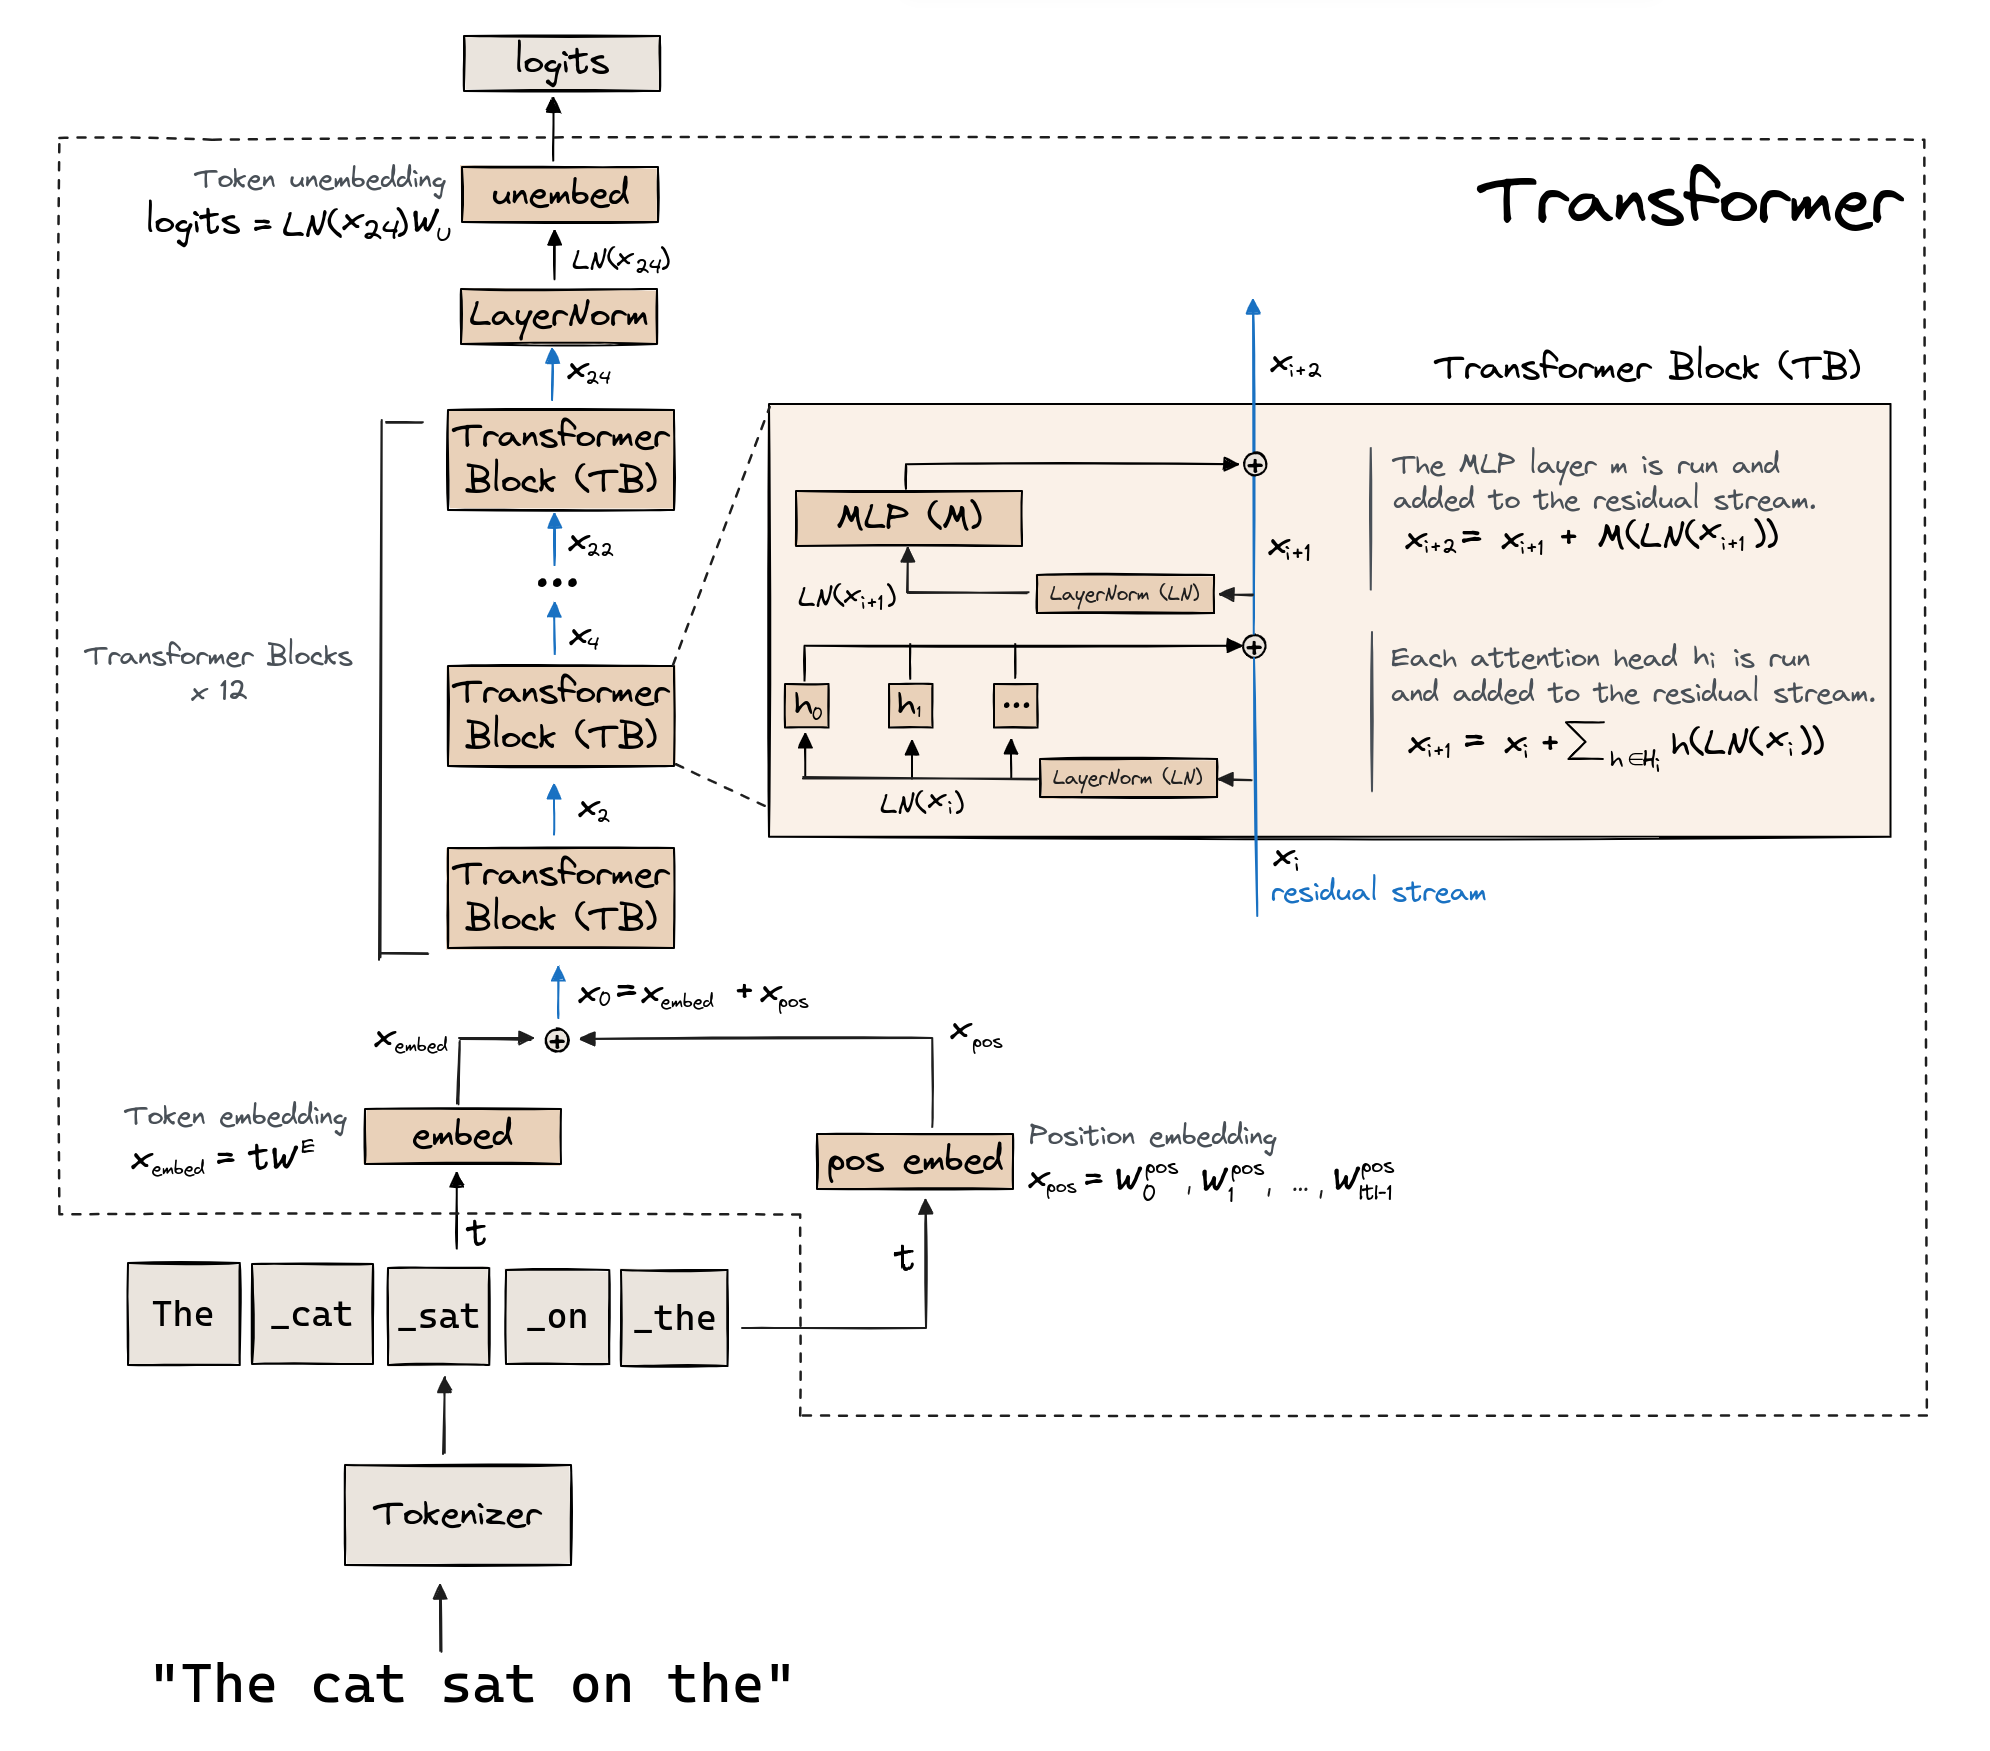
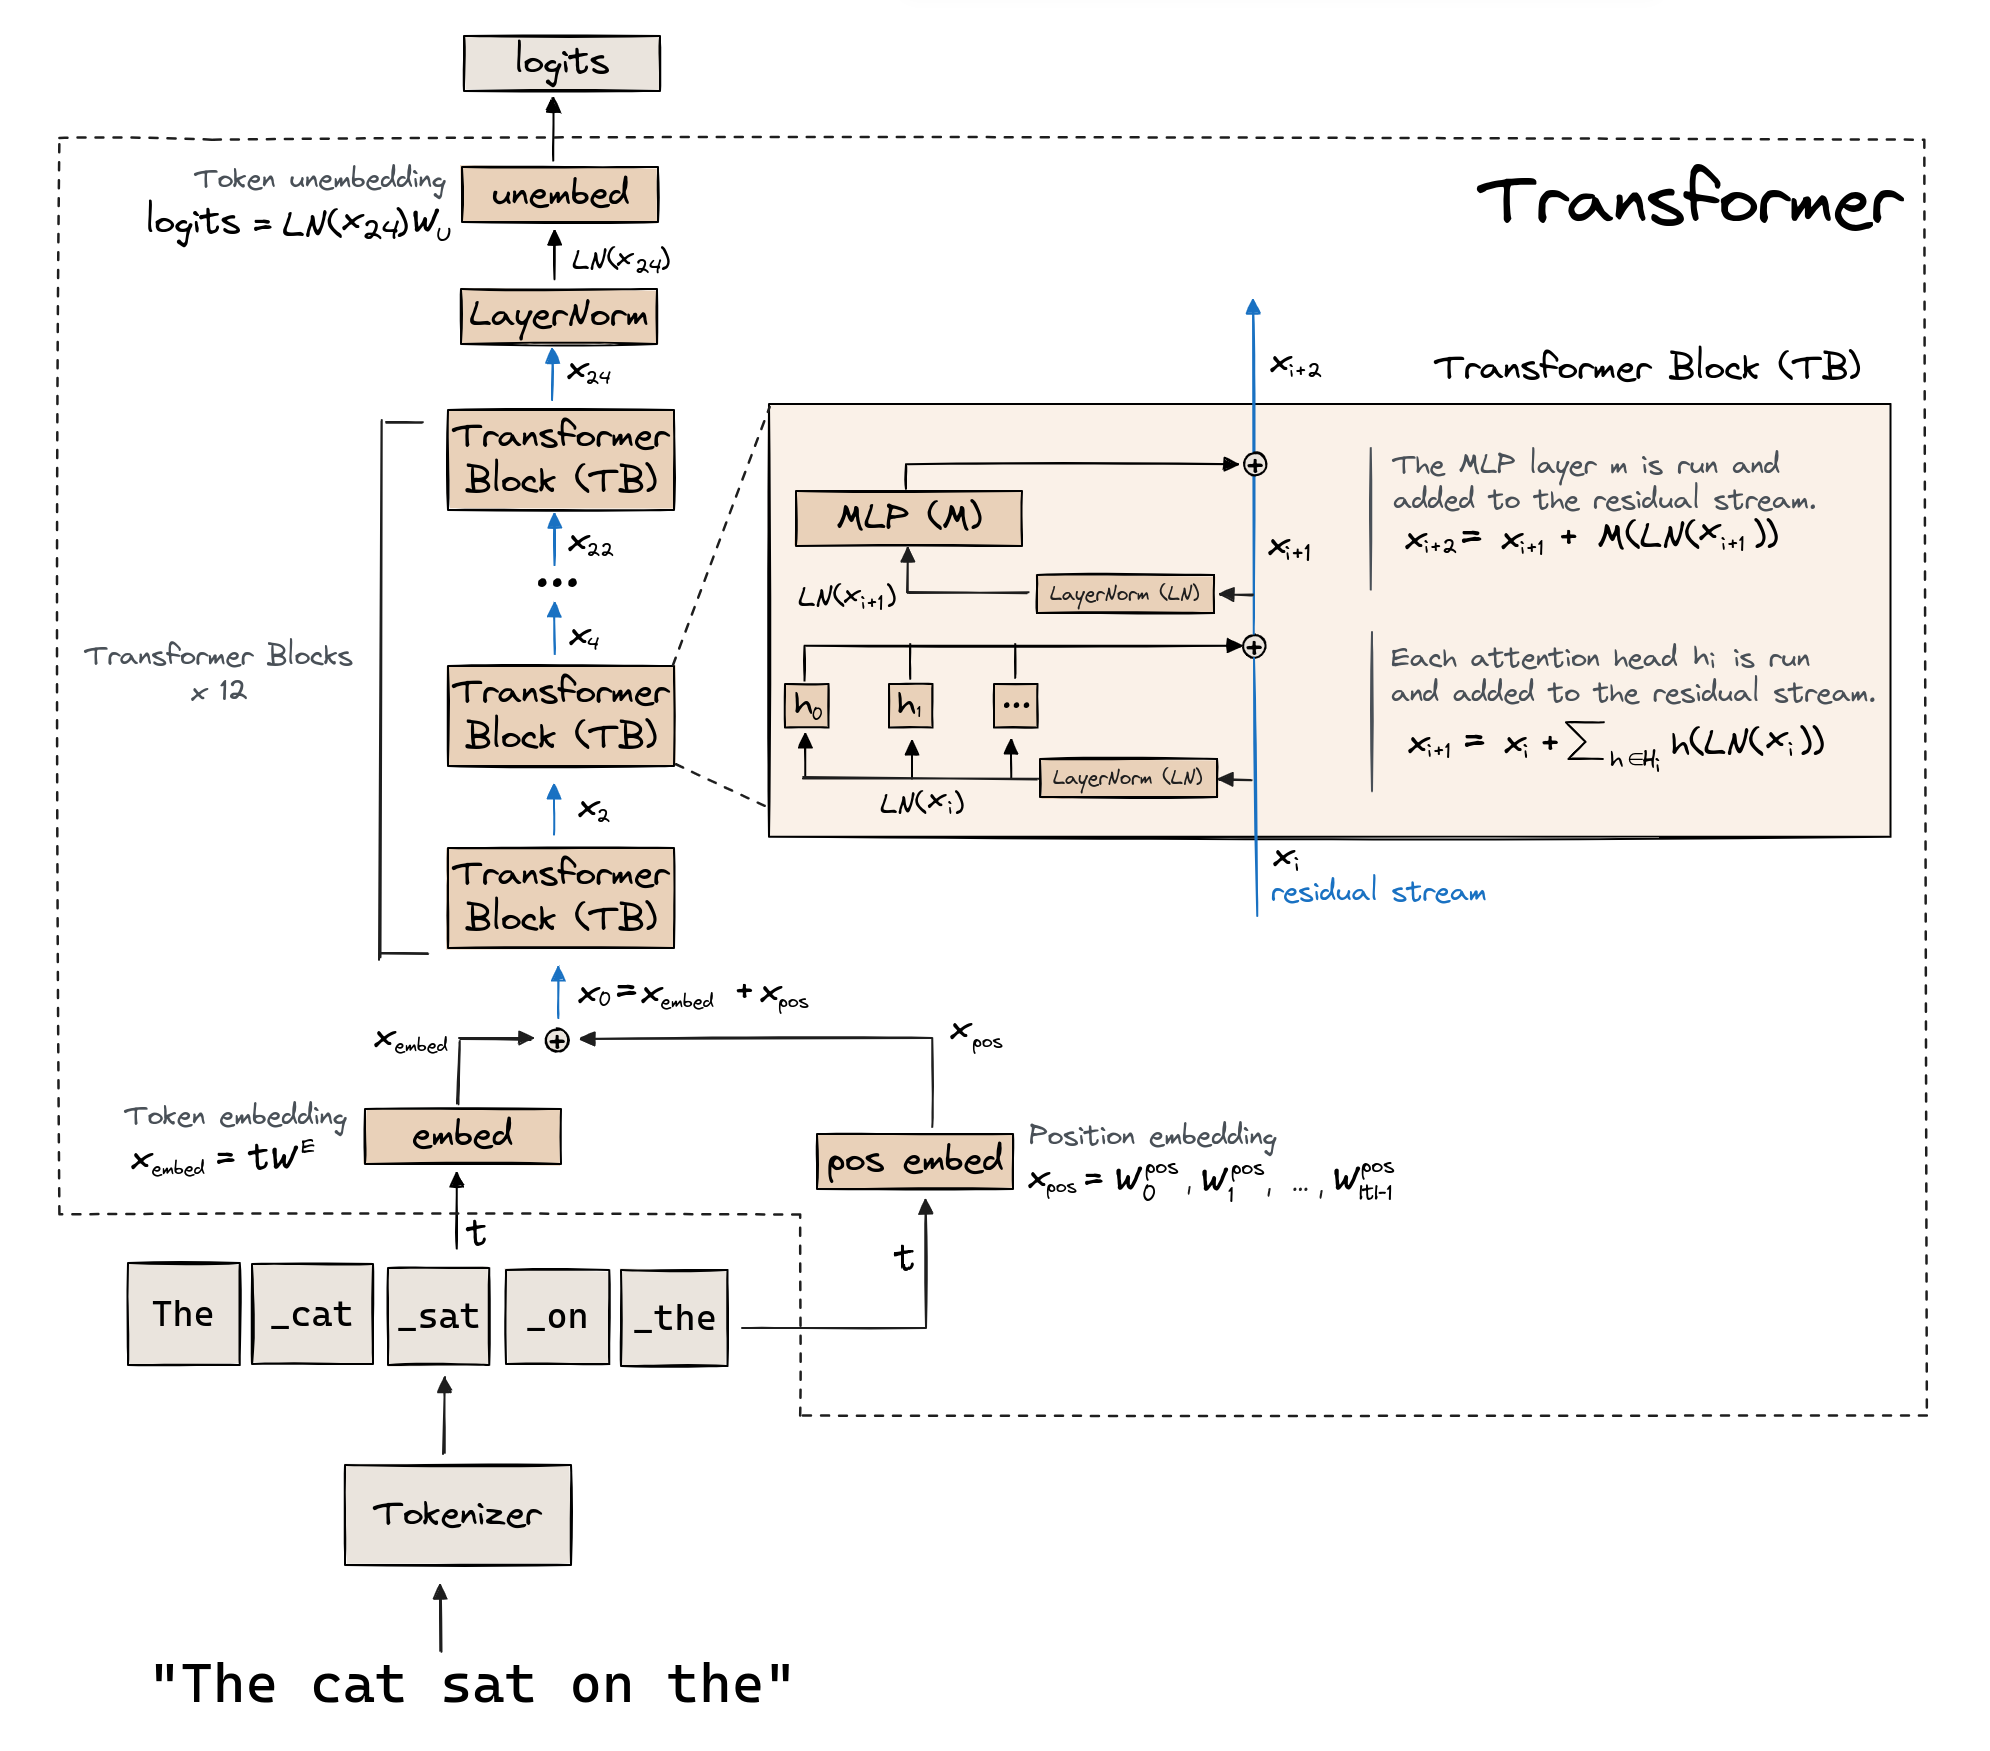

I currious about how x0 can be caculated.

In [2]:
import torch
import plotly.express as px
from transformer_lens import HookedTransformer

model = HookedTransformer.from_pretrained("gpt2-small")
W = model.W_pos[:100]  # [100, 768]

sim = torch.nn.functional.cosine_similarity(W[:, None, :], W[None, :, :], dim=-1)
px.imshow(sim.detach().cpu(), title="Cosine similarity giữa các vị trí").show()

`torch_dtype` is deprecated! Use `dtype` instead!


Loaded pretrained model gpt2-small into HookedTransformer
